<a href="https://colab.research.google.com/github/tejuchowdarii/Student_Placement_Data_Analysis/blob/main/processing_code_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# preprocessing and importing dataset and operating on it
from google.colab import files
uploaded=files.upload()
import pandas as pd
import numpy as np
df=pd.read_excel("placement_analysis_dataset.xlsx")



# 1. Load the dataset



print("Original Dataset Shape:", df.shape)
rows,columns=df.shape
print("Number of rows:", rows)
print("Number of columns:", columns)


# 2. Check missing values and duplicate values


print("\nMissing values before processing:")
print(df.isnull().sum())
total_duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {total_duplicates}")

print("\nUnprocessed Dataset:")
print(df.head())


# 3. Identify numerical columns


numerical_columns = df.select_dtypes(include=[np.number]).columns

print("\nNumerical columns:")
print(list(numerical_columns))

# 4. Handle missing values  in numerical columns


for column in numerical_columns:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)


# 5. Handle missing values in categorical columns


categorical_columns = df.select_dtypes(include=["object"]).columns

print("\nCategorical columns:")
print(list(categorical_columns))

for column in categorical_columns:
    # Find the most frequent value
    mode_value = df[column].mode()[0]

    # Replace missing values with mode
    df[column] = df[column].fillna(mode_value)



# 6. Display first 5 rows


print("\nProcessed Dataset:")
print(df.head())


# 7. Check missing values after processing


print("\nMissing values after processing:")
print(df.isnull().sum())


# 8. Total number of missing values


total_missing = df.isnull().sum().sum()

print("\nTotal missing values:", total_missing)


# 9. Save the processed dataset


output_file = "placement_analysis_dataset_cleaned.xlsx"

df.to_excel(output_file, index=False)

print("\nCleaned dataset saved as:", output_file)

Saving placement_analysis_dataset.xlsx to placement_analysis_dataset (5).xlsx
Original Dataset Shape: (5000, 13)
Number of rows: 5000
Number of columns: 13

Missing values before processing:
College_ID                      0
IQ_Score                      206
Previous_Semester_Result      228
CGPA                          155
Academic_Performance_Score    201
Internship_Experience         239
Extracurricular_Score         210
Communication_Skills_Score    258
Projects_Completed            197
Attendance_Rate               263
Technical_Skills_Score        249
Backlog_Count                 215
Placement_Status                0
dtype: int64
Total duplicate rows: 0

Unprocessed Dataset:
  College_ID  IQ_Score  Previous_Semester_Result   CGPA  \
0    CLG0001      85.0                      9.68   9.96   
1    CLG0001     108.0                      8.73   9.17   
2    CLG0001      82.0                      6.86   7.24   
3    CLG0001     105.0                      9.69  10.14   
4    CLG0001 

Saving placement_analysis_dataset_cleaned.xlsx to placement_analysis_dataset_cleaned (2).xlsx
Dataset Shape: (5000, 13)

Available Columns:
['College_ID', 'IQ_Score', 'Previous_Semester_Result', 'CGPA', 'Academic_Performance_Score', 'Internship_Experience', 'Extracurricular_Score', 'Communication_Skills_Score', 'Projects_Completed', 'Attendance_Rate', 'Technical_Skills_Score', 'Backlog_Count', 'Placement_Status']


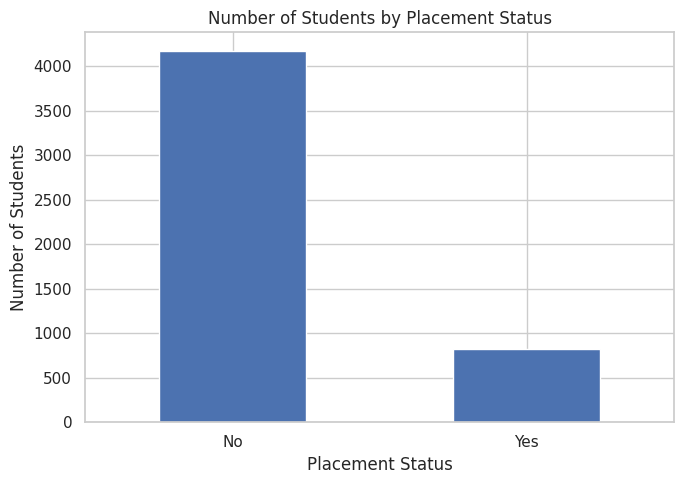

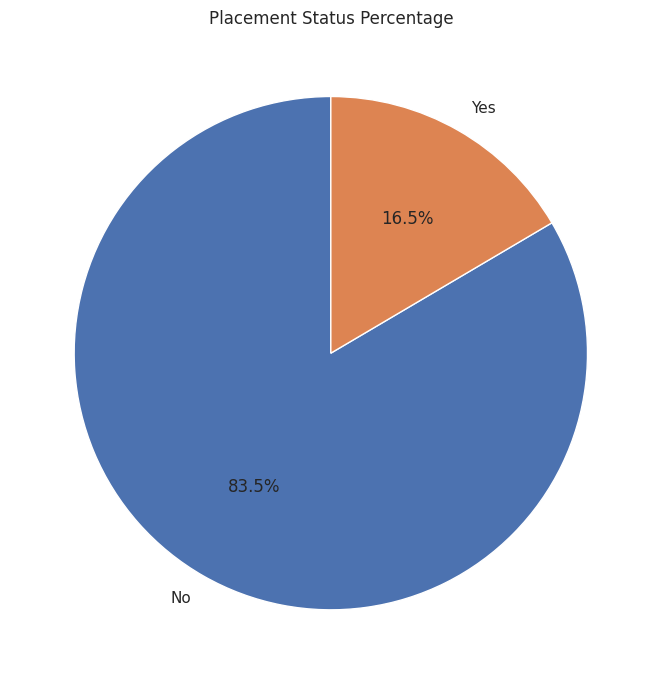

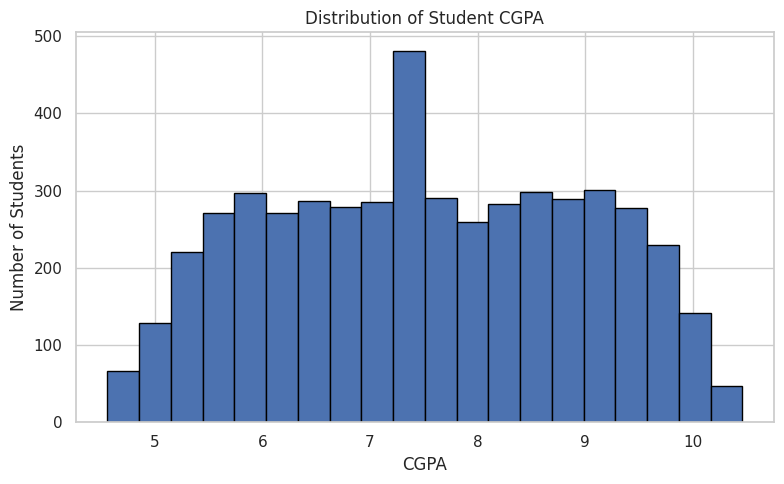

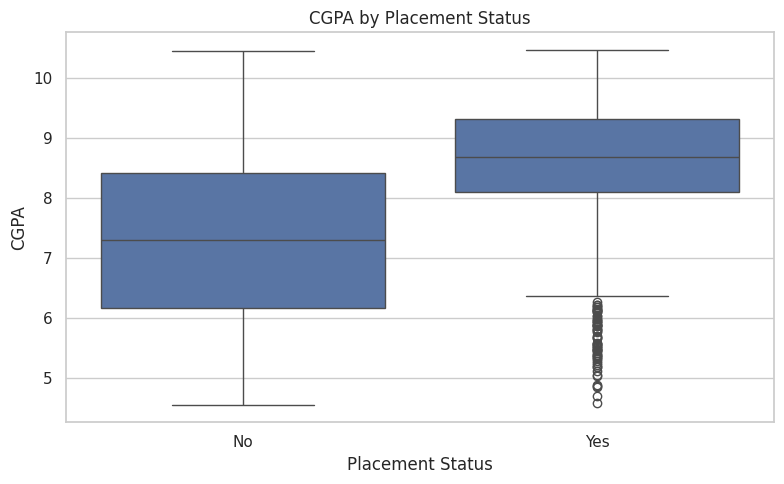

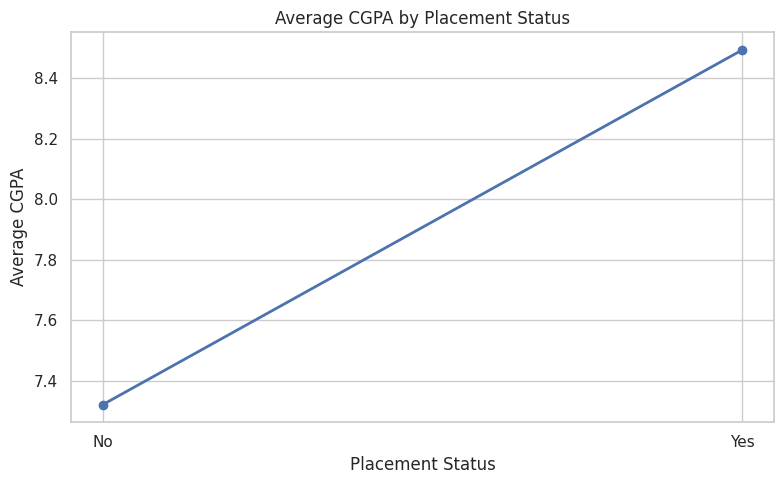

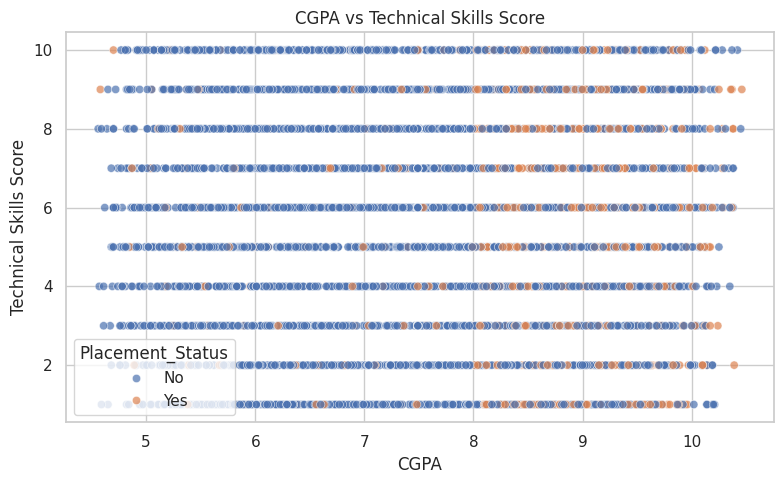

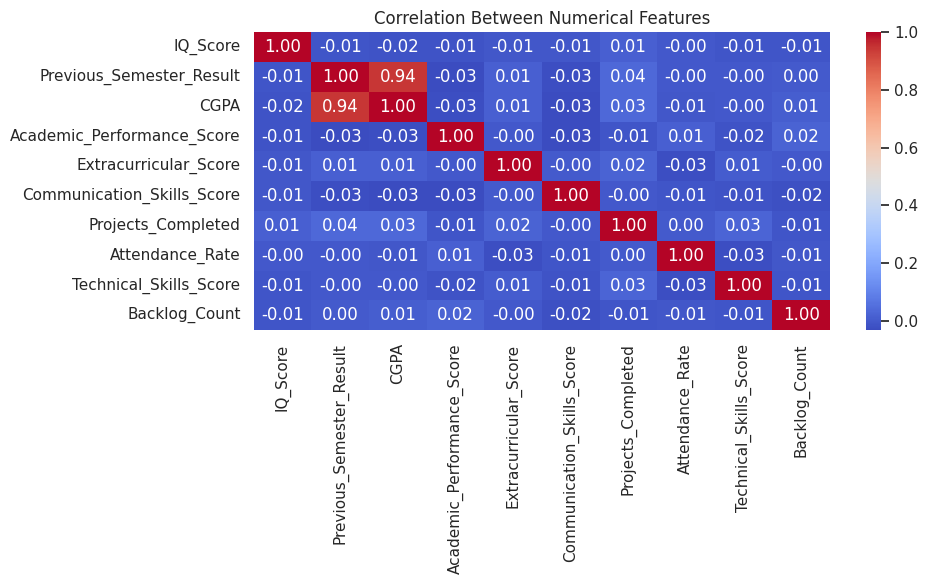


Placement Counts:
Placement_Status
No     4174
Yes     826
Name: count, dtype: int64

Placement Percentages:
Placement_Status
No     83.48
Yes    16.52
Name: count, dtype: float64

Average CGPA by Placement Status:
Placement_Status
No     7.322005
Yes    8.492446
Name: CGPA, dtype: float64

Graph analysis completed.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Load the cleaned dataset for graphical analysis

from google.colab import files
uploaded=files.upload()


df = pd.read_excel(
    "placement_analysis_dataset_cleaned.xlsx"
)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\nAvailable Columns:")
print(df.columns.tolist())

# Change this if your actual target column
# has a different name.
target = "Placement_Status"

if target not in df.columns:
    raise ValueError(
        "Placement_Status not found. "
        "Check the column names printed above."
    )

sns.set_theme(style="whitegrid")


# ---------------------------------------
# 2. BAR GRAPH
# Placement status count
# ---------------------------------------

placement_counts = df[target].value_counts()

plt.figure(figsize=(7, 5))
placement_counts.plot(kind="bar")

plt.title("Number of Students by Placement Status")
plt.xlabel("Placement Status")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ---------------------------------------
# 3. PIE CHART
# Placement percentage
# ---------------------------------------

plt.figure(figsize=(7, 7))

placement_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Placement Status Percentage")
plt.ylabel("")
plt.tight_layout()
plt.show()


# ---------------------------------------
# 4. HISTOGRAM
# Distribution of CGPA
# ---------------------------------------

if "CGPA" in df.columns:

    cgpa = pd.to_numeric(df["CGPA"], errors="coerce")

    plt.figure(figsize=(8, 5))
    plt.hist(
        cgpa.dropna(),
        bins=20,
        edgecolor="black"
    )

    plt.title("Distribution of Student CGPA")
    plt.xlabel("CGPA")
    plt.ylabel("Number of Students")
    plt.tight_layout()
    plt.show()


# ---------------------------------------
# 5. BOX PLOT
# CGPA by placement status
# ---------------------------------------

if "CGPA" in df.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x=target,
        y="CGPA"
    )

    plt.title("CGPA by Placement Status")
    plt.xlabel("Placement Status")
    plt.ylabel("CGPA")
    plt.tight_layout()
    plt.show()


# ---------------------------------------
# 6. LINE CHART
# Average CGPA by placement status
# ---------------------------------------

if "CGPA" in df.columns:

    average_cgpa = df.groupby(target)["CGPA"].mean()

    plt.figure(figsize=(8, 5))

    plt.plot(
        average_cgpa.index.astype(str),
        average_cgpa.values,
        marker="o",
        linewidth=2
    )

    plt.title("Average CGPA by Placement Status")
    plt.xlabel("Placement Status")
    plt.ylabel("Average CGPA")
    plt.tight_layout()
    plt.show()


# ---------------------------------------
# 7. SCATTER PLOT
# CGPA vs Technical Skills Score
# ---------------------------------------

if (
    "CGPA" in df.columns
    and "Technical_Skills_Score" in df.columns
):

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x="CGPA",
        y="Technical_Skills_Score",
        hue=target,
        alpha=0.7
    )

    plt.title("CGPA vs Technical Skills Score")
    plt.xlabel("CGPA")
    plt.ylabel("Technical Skills Score")
    plt.tight_layout()
    plt.show()


# ---------------------------------------
# 8. CORRELATION HEATMAP
# Relationship between numerical features
# ---------------------------------------

numerical_df = df.select_dtypes(
    include=np.number
)

if numerical_df.shape[1] >= 2:

    plt.figure(figsize=(10, 6))

    sns.heatmap(
        numerical_df.corr(),
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Between Numerical Features")
    plt.tight_layout()
    plt.show()


# ---------------------------------------
# 9. PRINT BASIC ANALYSIS
# ---------------------------------------

print("\nPlacement Counts:")
print(placement_counts)

print("\nPlacement Percentages:")
print(
    (placement_counts / placement_counts.sum() * 100)
    .round(2)
)

if "CGPA" in df.columns:
    print("\nAverage CGPA by Placement Status:")
    print(df.groupby(target)["CGPA"].mean())

print("\nGraph analysis completed.")

In [ ]:
def predict_placement_direct(student):
    # Rule 1: Instant rejection if there are backlogs
    if student["Backlog_Count"] > 0:
        return "No"

    # Rule 2: Strong pass if academic and technical credentials are high
    if student["CGPA"] >= 8.0 and student["Technical_Skills_Score"] >= 7:
        return "Yes"

    # Rule 3: Moderate pass if CGPA is decent and they have good projects
    if student["CGPA"] >= 7.5 and student["Projects_Completed"] >= 3:
        return "Yes"

    # Default fallback
    return "No"

# Get dynamic input from the user
print("Enter the student details:")
student_data = {
    "CGPA": float(input("Enter CGPA: ")),
    "Technical_Skills_Score": float(input("Enter Technical Skills Score: ")),
    "Attendance_Rate": float(input("Enter Attendance Rate: ")),
    "Projects_Completed": int(input("Enter Projects Completed: ")),
    "Backlog_Count": int(input("Enter Backlog Count: "))
}

# Run the prediction
status = predict_placement_direct(student_data)
print(f"\nPredicted Placement Status: {status}")

Enter the student details:
Enter CGPA: 9.1
Enter Technical Skills Score: 8
Enter Attendance Rate: 87
Enter Projects Completed: 4
Enter Backlog Count: 0

Predicted Placement Status: Yes


In [ ]:

def predict_placement_direct(student):

    # Rule 1: Check backlogs first
    if student["Backlog_Count"] > 0:
        return "No"

    # Rule 2: Check CGPA and technical skills
    if (student["CGPA"] >= 8.0 and
            student["Technical_Skills_Score"] >= 7):
        return "Yes"

    # Rule 3: Check CGPA and completed projects
    if (student["CGPA"] >= 7.5 and
            student["Projects_Completed"] >= 3):
        return "Yes"

    # Default result
    return "No"


# Get student details from the user
student_data = {
    "CGPA": float(input("Enter CGPA: ")),
    "Technical_Skills_Score": float(
        input("Enter Technical Skills Score: ")
    ),
    "Projects_Completed": int(
        input("Enter Projects Completed: ")
    ),
    "Backlog_Count": int(
        input("Enter Backlog Count: ")
    )
}

# Predict the placement status
status = predict_placement_direct(student_data)

if status == "Yes":
    print("Predicted Placement Status: Placed")
else:
    print("Predicted Placement Status: Not Placed")
